# 6. Probability of default: scorecard vs machine learning

Banks have scored loans with **logistic regression scorecards** for decades: a few binned variables, a points table a loan officer can read, and coefficients a regulator can audit. Fintechs often use **gradient boosting** (XGBoost, LightGBM) instead, and neural networks are the default in many other fields. This notebook asks the practical question a model-risk team would ask:

> **Does machine learning predict mortgage default better than a scorecard, and does the gain survive when the economy changes?**

Five models are built on the same data and the same features, fitted on 2006 loans and judged twice: on unseen 2006 loans (*in time*) and on 2017 loans (*out of time*, a different economy). They are compared on discrimination (AUC, Gini, KS), calibration and stability (PSI), and the best boosting model is opened up with SHAP values.

In [1]:
import sys
sys.path.insert(0, "../src")
import warnings
warnings.filterwarnings("ignore")

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb
from scipy.stats import ks_2samp
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from credit_risk.data import load_loans

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, GREY = "#1a73e8", "#d93025", "#188038", "#e37400", "#80868b"
SEED = 2026

## The target: default within three years

Notebooks 2 and 3 modelled *time* to default. Retail scorecards instead predict a yes/no outcome over a fixed horizon. Here a loan is **bad** if it defaulted (adjusted definition from notebook 1: 90+ days delinquent outside payment relief, or a credit-event termination) within **36 months** of its first payment. Only 30-year loans are kept, so every loan has the same horizon.

Prepayment competes with default: a loan prepaid in month 20 did *not* default within the window, so it counts as good. That makes the target the cumulative incidence of default at 36 months from notebook 2, not the naive Kaplan-Meier version. Loans that left the sample early for other reasons (sold or repurchased) have an unknown outcome and are excluded; there are very few.

In [2]:
HORIZON = 36
loans = load_loans((2006, 2017))
loans = loans[loans["term"] == 360].copy()

loans["bad"] = ((loans["event"] == 1) & (loans["time"] <= HORIZON)).astype(int)
# A loan that left the sample (sold, repurchased) before 36 months without defaulting has an
# unknown outcome: it is excluded. Prepaid loans did not default within the window: bad = 0.
unknown = (loans["event"] == 0) & (loans["time"] < HORIZON)
excluded = loans[unknown].groupby("vintage").size()
loans = loans[~unknown]

summary = loans.groupby("vintage").agg(loans=("bad", "size"), bad_loans=("bad", "sum"), bad_rate=("bad", "mean"))
summary["excluded (unknown outcome)"] = excluded
summary

,loans,bad_loans,bad_rate,excluded (unknown outcome)
vintage,,,,
2006,42104,2857,0.068,29
2017,39373,529,0.013,86


## Features and samples

All models get the same origination variables: credit score, loan-to-value (LTV and combined CLTV), debt-to-income, the rate premium over the year's median rate (as in notebook 3), loan size, number of borrowers, occupancy, purpose, channel, property type and first-time-buyer flag. The property state is left out on purpose: a model trained on 2006 would learn *where the 2008 crisis hit* (California, Florida, Nevada, Arizona), which says little about 2017 borrowers.

The 2006 vintage is split 70/30 into training and test samples, stratified by the target. The 2017 vintage is the out-of-time sample. Its bad rate is about one fifth of 2006's, the same environment effect the Cox model found.

In [3]:
loans["rate_premium"] = loans["rate"] - loans.groupby("vintage")["rate"].transform("median")
loans["log_upb"] = np.log(loans["upb"])
loans["first_time_buyer"] = loans["first_time_buyer"].replace({"9": "U"}).fillna("U")

NUM = ["fico", "ltv", "cltv", "dti", "rate_premium", "log_upb", "n_borrowers"]
CAT = ["occupancy", "purpose", "channel", "property_type", "first_time_buyer"]
loans = loans.dropna(subset=["fico", "ltv", "cltv", "dti"])
for c in CAT:
    loans[c] = loans[c].fillna("U").astype(str)
loans["fico"] = loans["fico"].astype(float)

dev = loans[loans["vintage"] == 2006]
oot = loans[loans["vintage"] == 2017]
train, test = train_test_split(dev, test_size=0.3, stratify=dev["bad"], random_state=SEED)
pd.DataFrame({"sample": ["train (2006, 70%)", "test (2006, 30%)", "out of time (2017)"],
              "loans": [len(train), len(test), len(oot)],
              "bad rate": [train["bad"].mean(), test["bad"].mean(), oot["bad"].mean()]})

,sample,loans,bad rate
0,"train (2006, 70%)",28797,0.068
1,"test (2006, 30%)",12342,0.068
2,out of time (2017),38497,0.013


## Model 1: a bank-style scorecard (logistic regression on weights of evidence)

The classic scorecard recipe, written out step by step:

1. **Bin** each numeric variable (here: six quantile bins learned on the training data only).
2. Replace each bin by its **weight of evidence**, WoE = log(share of goods in the bin / share of bads in the bin). Positive WoE means safer than average.
3. Rank variables by **information value**, IV = Σ (share of goods − share of bads) × WoE. Usual reading: below 0.02 useless, 0.02–0.1 weak, 0.1–0.3 medium, above 0.3 strong.
4. Fit a **logistic regression on the WoE values** and scale the coefficients to **points**.

The WoE transformation makes every variable's relationship with the log-odds piecewise linear and lets the analyst inspect and override every bin, which is why validators like it.

In [4]:
def woe_table(x, y, bins):
    """Weight of evidence and information value of one binned variable."""
    t = pd.crosstab(bins, y)
    t.columns = ["good", "bad"]
    t = t + 0.5                                       # avoids log(0) in sparse bins
    dist_good, dist_bad = t["good"] / t["good"].sum(), t["bad"] / t["bad"].sum()
    t["bad rate"] = t["bad"] / (t["good"] + t["bad"])
    t["woe"] = np.log(dist_good / dist_bad)
    t["iv"] = (dist_good - dist_bad) * t["woe"]
    return t


def make_bins(train_col, col_name):
    """Quantile cut points learned on the training sample only."""
    if col_name in NUM and train_col.nunique() > 6:
        edges = np.unique(np.quantile(train_col, np.linspace(0, 1, 7)))
        edges[0], edges[-1] = -np.inf, np.inf
        return lambda s: pd.cut(s, edges, include_lowest=True).astype(str)
    return lambda s: s.astype(str)


binners, woe_maps, iv = {}, {}, {}
for c in NUM + CAT:
    binners[c] = make_bins(train[c], c)
    t = woe_table(train[c], train["bad"], binners[c](train[c]))
    woe_maps[c], iv[c] = t["woe"], t["iv"].sum()

iv = pd.Series(iv).sort_values(ascending=False).rename("information value")
iv.to_frame()

,information value
fico,7.704e-01
ltv,1.931e-01
cltv,1.319e-01
dti,1.198e-01
n_borrowers,9.504e-02
rate_premium,8.332e-02
purpose,6.058e-02
log_upb,2.861e-02
occupancy,2.624e-02
property_type,1.602e-02


The credit score dominates (IV 0.77; above 0.5 a validator would normally check for leakage, but FICO is a genuinely strong predictor of mortgage default). Leverage (LTV, CLTV), debt-to-income, the number of borrowers and the rate premium follow. Property type, channel and first-time-buyer status fall below 0.02 and are dropped from the scorecard (the machine-learning models still see them). The bins for the credit score:

In [5]:
woe_table(train["fico"], train["bad"], binners["fico"](train["fico"]))[["good", "bad", "bad rate", "woe"]]

,good,bad,bad rate,woe
fico,,,,
"(-inf, 663.0]",4095.5,816.5,0.166,-1.003
"(663.0, 697.0]",4228.5,487.5,0.103,-0.455
"(697.0, 728.0]",4591.5,305.5,0.062,0.095
"(728.0, 758.0]",4604.5,200.5,0.042,0.519
"(758.0, 784.0]",4748.5,103.5,0.021,1.211
"(784.0, inf]",4571.5,49.5,0.011,1.910


The bad rate falls steadily from 16.6% in the lowest band to 1.1% in the highest, and the WoE rises accordingly: a monotone, explainable pattern.

In [6]:
SC_VARS = [c for c in iv.index if iv[c] >= 0.02]       # usual rule: drop IV < 0.02 (no predictive power)


def to_woe(df):
    return pd.DataFrame({c: binners[c](df[c]).map(woe_maps[c]).fillna(0).astype(float) for c in SC_VARS},
                        index=df.index)


scorecard = LogisticRegression(C=1e6, max_iter=1000).fit(to_woe(train), train["bad"])
coef = pd.Series(scorecard.coef_[0], index=SC_VARS)

# Scaling to points: 600 points = odds 30:1 (good:bad), and 20 points double the odds (PDO = 20)
PDO, BASE_SCORE, BASE_ODDS = 20, 600, 30
factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)
n = len(SC_VARS)
points = []
for c in SC_VARS:
    for b, w in woe_maps[c].items():
        points.append({"variable": c, "bin": b,
                       "points": round(-(coef[c] * w + scorecard.intercept_[0] / n) * factor + offset / n)})
points = pd.DataFrame(points)
pd.DataFrame({"coefficient": coef}).T

,fico,ltv,cltv,dti,n_borrowers,rate_premium,purpose,log_upb,occupancy
coefficient,-0.916,-0.49,-0.479,-0.529,-1.191,-0.63,-0.805,-1.706,-0.31


In [7]:
points[points["variable"].isin(["fico", "ltv"])]

,variable,bin,points
0,fico,"(-inf, 663.0]",38
1,fico,"(663.0, 697.0]",52
2,fico,"(697.0, 728.0]",67
3,fico,"(728.0, 758.0]",78
4,fico,"(758.0, 784.0]",96
5,fico,"(784.0, inf]",115
6,ltv,"(-inf, 56.0]",77
7,ltv,"(56.0, 70.0]",66
8,ltv,"(70.0, 79.0]",63
9,ltv,"(79.0, 80.0]",65


With the scaling used here (600 points at good:bad odds of 30:1, and 20 more points doubling the odds), the credit score is worth between 38 and 115 points. The LTV row shows something a scorecard makes visible: loans at exactly 80% LTV score *slightly better* than those at 70–79%, because 80% is the largest down-payment threshold at which US borrowers avoid mortgage insurance, and many solid borrowers sit exactly there. Above 80% risk jumps. An analyst would decide whether to keep that non-monotone bin or merge it; a black-box model makes the same decision silently. All coefficients are negative, as they should be: higher WoE (safer bin) means lower log-odds of default.

## Models 2 and 3: gradient boosting (XGBoost and LightGBM)

**Gradient boosting** builds hundreds of small decision trees in sequence; each new tree is fitted to the errors of the ones before it, and the prediction is the sum of all trees. It captures non-linear effects and interactions without anyone specifying them. XGBoost and LightGBM are two efficient implementations of the same idea (LightGBM grows trees leaf by leaf and is usually faster).

The main risk is **overfitting**: with enough trees the model memorises the training data. It is controlled with a small learning rate, shallow trees, a minimum number of loans per leaf, random subsampling of rows and columns, and **early stopping**: part of the training data is held back and trees are added only while the AUC on that slice keeps improving.

A third variant forces LightGBM to be **monotone**: risk may only fall as FICO rises and only rise with LTV, CLTV, DTI and the rate premium. This is how boosting models are made acceptable to credit validators: no unexplainable wiggles.

In [8]:
def as_frame(df):
    X = df[NUM + CAT].copy()
    for c in CAT:
        X[c] = pd.Categorical(X[c], categories=sorted(loans[c].unique()))
    return X


X_tr, X_te, X_oot = as_frame(train), as_frame(test), as_frame(oot)
# A slice of the training data is held back only to decide when to stop adding trees
X_fit, X_stop, y_fit, y_stop = train_test_split(X_tr, train["bad"], test_size=0.2,
                                                stratify=train["bad"], random_state=SEED)

xgb_model = xgb.XGBClassifier(
    n_estimators=2000, learning_rate=0.03, max_depth=4, min_child_weight=20,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    enable_categorical=True, tree_method="hist", eval_metric="auc",
    early_stopping_rounds=100, random_state=SEED)
xgb_model.fit(X_fit, y_fit, eval_set=[(X_stop, y_stop)], verbose=False)

lgb_params = dict(n_estimators=2000, learning_rate=0.03, num_leaves=15, min_child_samples=100,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                  random_state=SEED, verbose=-1)
lgb_model = lgb.LGBMClassifier(**lgb_params)
lgb_model.fit(X_fit, y_fit, eval_set=[(X_stop, y_stop)], eval_metric="auc",
              callbacks=[lgb.early_stopping(100, verbose=False)])

# Same LightGBM, but forced to be monotone where credit logic demands it:
# risk can only fall with FICO and only rise with LTV, CLTV, DTI and the rate premium.
mono = [{"fico": -1, "ltv": 1, "cltv": 1, "dti": 1, "rate_premium": 1}.get(c, 0) for c in NUM + CAT]
lgb_mono = lgb.LGBMClassifier(**lgb_params, monotone_constraints=mono, monotone_constraints_method="advanced")
lgb_mono.fit(X_fit, y_fit, eval_set=[(X_stop, y_stop)], eval_metric="auc",
             callbacks=[lgb.early_stopping(100, verbose=False)])

pd.DataFrame({"trees kept by early stopping": [xgb_model.best_iteration + 1, lgb_model.best_iteration_,
                                                lgb_mono.best_iteration_]},
             index=["XGBoost", "LightGBM", "LightGBM (monotone)"])

,trees kept by early stopping
XGBoost,195
LightGBM,117
LightGBM (monotone),144


## Model 4: a small neural network

A multilayer perceptron with two hidden layers (32 and 16 neurons), standardised numeric inputs and one-hot categorical inputs, weight decay and early stopping. It is included as a benchmark: on tabular data like this, neural networks rarely beat boosting, and the comparison shows why.

In [9]:
prep = ColumnTransformer([("num", StandardScaler(), NUM),
                          ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
mlp = make_pipeline(prep, MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, learning_rate_init=1e-3,
                                        early_stopping=True, validation_fraction=0.2, n_iter_no_change=20,
                                        max_iter=500, random_state=SEED))
mlp.fit(train[NUM + CAT], train["bad"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('mlpclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['fico','ltv','cltv',...,'channel','property_type','first_time_buyer']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthro

## Comparison: discrimination and calibration

- **AUC**: probability that a randomly chosen bad loan gets a higher predicted risk than a randomly chosen good one (0.5 = coin flip, 1 = perfect ranking). **Gini** = 2·AUC − 1, the version banks report.
- **KS**: largest gap between the cumulative score distributions of bads and goods.

All three measure *ranking*, not whether the predicted probabilities are right; calibration is checked separately below.

In [10]:
def ks_stat(y, p):
    return ks_2samp(p[y == 1], p[y == 0]).statistic


predict = {
    "Scorecard (logistic + WoE)": lambda d: scorecard.predict_proba(to_woe(d))[:, 1],
    "XGBoost": lambda d: xgb_model.predict_proba(as_frame(d))[:, 1],
    "LightGBM": lambda d: lgb_model.predict_proba(as_frame(d))[:, 1],
    "LightGBM (monotone)": lambda d: lgb_mono.predict_proba(as_frame(d))[:, 1],
    "Neural network (MLP)": lambda d: mlp.predict_proba(d[NUM + CAT])[:, 1],
}
samples = {"test 2006": test, "out of time 2017": oot}
preds = {(m, s): f(d) for m, f in predict.items() for s, d in samples.items()}

rows = []
for m in predict:
    r = {"model": m}
    for s, d in samples.items():
        p, y = preds[(m, s)], d["bad"].to_numpy()
        auc = roc_auc_score(y, p)
        r[f"AUC {s}"], r[f"Gini {s}"], r[f"KS {s}"] = auc, 2 * auc - 1, ks_stat(y, p)
        r[f"mean PD {s}"] = p.mean()
    rows.append(r)
metrics = pd.DataFrame(rows).set_index("model")
metrics.to_csv("../results/pd_model_comparison.csv")
metrics[[c for c in metrics.columns if not c.startswith("mean PD")]]

,AUC test 2006,Gini test 2006,KS test 2006,AUC out of time 2017,Gini out of time 2017,KS out of time 2017
model,,,,,,
Scorecard (logistic + WoE),0.766,0.533,0.408,0.767,0.534,0.412
XGBoost,0.773,0.546,0.428,0.764,0.527,0.411
LightGBM,0.772,0.544,0.428,0.765,0.531,0.417
LightGBM (monotone),0.773,0.547,0.427,0.764,0.529,0.423
Neural network (MLP),0.778,0.557,0.438,0.731,0.461,0.358


On unseen 2006 loans, every machine-learning model ranks slightly better than the scorecard: Gini 0.54–0.56 against 0.53. On 2017 loans the order changes: the boosting models tie with the scorecard, and the neural network falls clearly behind (Gini 0.46). Is the in-time gain real? A paired bootstrap of the AUC difference against the scorecard:

In [11]:
# Is the gain of the best model over the scorecard real? Paired bootstrap of the AUC difference.
rng = np.random.default_rng(SEED)


def auc_gain_ci(model, sample, reps=300):
    y = samples[sample]["bad"].to_numpy()
    p1, p0 = preds[(model, sample)], preds[("Scorecard (logistic + WoE)", sample)]
    diffs = []
    for _ in range(reps):
        i = rng.integers(0, len(y), len(y))
        diffs.append(roc_auc_score(y[i], p1[i]) - roc_auc_score(y[i], p0[i]))
    return np.percentile(diffs, [2.5, 50, 97.5])


gain = pd.DataFrame([{"model": m, "sample": s, **dict(zip(["2.5%", "median", "97.5%"], auc_gain_ci(m, s)))}
                     for m in ["XGBoost", "LightGBM", "Neural network (MLP)"] for s in samples])
gain.rename(columns=lambda c: f"AUC gain vs scorecard, {c}" if "%" in c or c == "median" else c)

,model,sample,"AUC gain vs scorecard, 2.5%","AUC gain vs scorecard, median","AUC gain vs scorecard, 97.5%"
0,XGBoost,test 2006,8.726e-04,0.007,0.012
1,XGBoost,out of time 2017,-1.017e-02,-0.004,0.004
2,LightGBM,test 2006,-1.430e-03,0.005,0.012
3,LightGBM,out of time 2017,-9.229e-03,-0.002,0.006
4,Neural network (MLP),test 2006,6.165e-03,0.012,0.019
5,Neural network (MLP),out of time 2017,-4.684e-02,-0.037,-0.025


- **In time**, the gains are at most about one AUC point: about +0.007 for XGBoost and +0.012 for the neural network (intervals exclude zero), and +0.005 for LightGBM (interval includes zero).
- **Out of time**, no model beats the scorecard: the boosting intervals straddle zero, and the neural network *loses* almost 0.04 AUC (interval −0.047 to −0.025).

The extra flexibility bought a small improvement on loans from the same year and nothing on a different economy. The neural network, the most flexible model, learned patterns specific to 2006 that did not carry over.

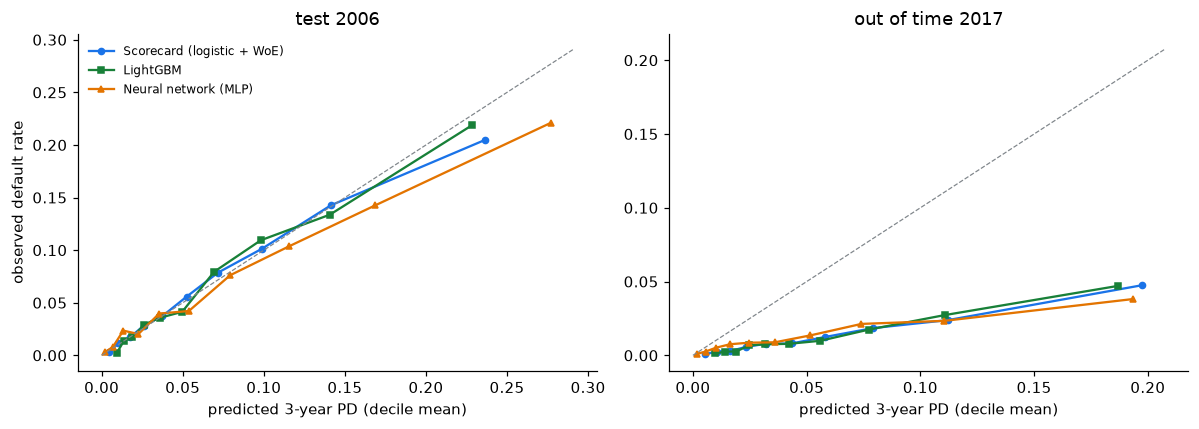

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
styles = {"Scorecard (logistic + WoE)": (BLUE, "o-"), "LightGBM": (GREEN, "s-"), "Neural network (MLP)": (ORANGE, "^-")}
for ax, (s, d) in zip(axes, samples.items()):
    for m, (col, st) in styles.items():
        p = preds[(m, s)]
        dec = pd.qcut(p, 10, labels=False, duplicates="drop")
        cal = pd.DataFrame({"pred": p, "obs": d["bad"].to_numpy(), "dec": dec}).groupby("dec").mean()
        ax.plot(cal["pred"], cal["obs"], st, color=col, label=m, ms=4)
    lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([0, lim], [0, lim], color=GREY, lw=0.8, ls="--")
    ax.set_xlabel("predicted 3-year PD (decile mean)")
    ax.set_title(s)
axes[0].set_ylabel("observed default rate")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("../figures/pd_calibration_ml.png", bbox_inches="tight")
plt.show()

In 2006 all models are well calibrated (the neural network overpredicts in the riskiest decile). In 2017 **every** model overpredicts default by a factor of about four: the average predicted 3-year PD is 5–6% against an observed 1.3%. That is the finding of notebook 3 again, now for every model class: **ranking transfers across economies, the level of risk does not.** No algorithm fixes this, because the missing information (house prices, unemployment) is not in the origination data. In practice the model would be recalibrated to the current portfolio, or macroeconomic variables would be added, which is what IFRS 9 and stress testing require.

In [13]:
def psi(expected, actual, bins=10):
    """Population stability index between two score distributions (deciles of the expected one)."""
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return np.sum((a - e) * np.log(a / e))


pd.DataFrame({"PSI 2006 test -> 2017": {m: psi(preds[(m, "test 2006")], preds[(m, "out of time 2017")])
                                        for m in predict}})

,PSI 2006 test -> 2017
Scorecard (logistic + WoE),0.046
XGBoost,0.062
LightGBM,0.049
LightGBM (monotone),0.055
Neural network (MLP),0.115


The **population stability index** compares the distribution of scores between development and application samples (rule of thumb: below 0.1 stable, 0.1–0.25 monitor, above 0.25 redevelop). The scorecard is the most stable model and the neural network the least, above 0.1. Validators monitor this number every quarter.

## Opening the black box: SHAP values

Boosting models have no coefficients. **SHAP values** fill the gap: for each loan they split the prediction (in log-odds) into one contribution per variable, using a game-theory rule that makes the contributions add up exactly to the prediction. Averaging their absolute size gives a variable importance; plotting them against a variable shows the shape of its effect.

In [14]:
explainer = shap.TreeExplainer(lgb_model)
X_shap = X_te.sample(5000, random_state=SEED)
sv = explainer.shap_values(X_shap)
sv = sv[1] if isinstance(sv, list) else sv
importance = pd.Series(np.abs(sv).mean(axis=0), index=X_shap.columns).sort_values(ascending=False)
importance.rename("mean |SHAP| (log-odds)").to_frame()

,mean |SHAP| (log-odds)
fico,0.657
n_borrowers,0.258
log_upb,0.191
ltv,0.187
purpose,0.181
dti,0.116
cltv,0.115
rate_premium,0.078
channel,0.017
occupancy,0.008


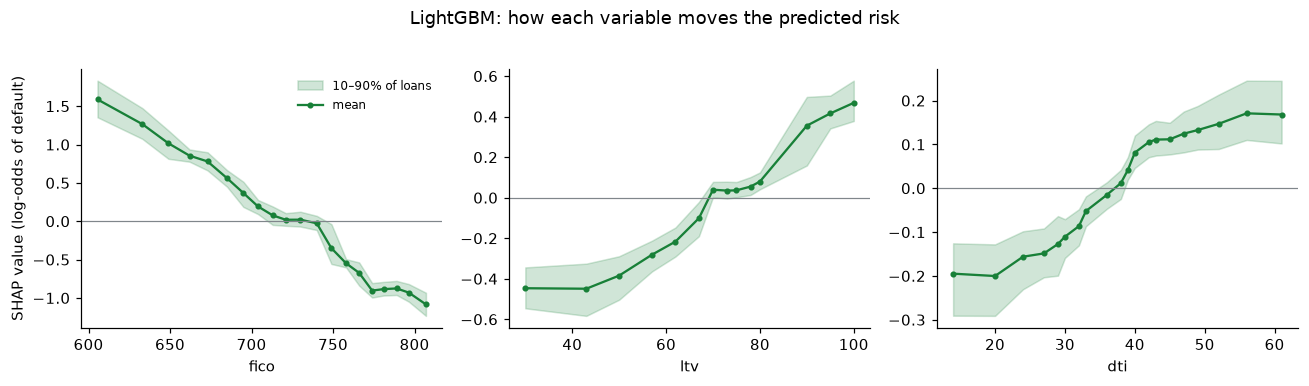

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
# Aggregates only (no individual loans are plotted): mean SHAP value and its 10-90% range
# within 20 quantile groups of each variable.
for ax, c in zip(axes, ["fico", "ltv", "dti"]):
    j = list(X_shap.columns).index(c)
    g = pd.DataFrame({"x": X_shap[c].to_numpy(), "s": sv[:, j]})
    g["bin"] = pd.qcut(g["x"], 20, duplicates="drop")
    agg = g.groupby("bin", observed=True).agg(x=("x", "median"), mean=("s", "mean"),
                                              lo=("s", lambda v: v.quantile(0.1)),
                                              hi=("s", lambda v: v.quantile(0.9)))
    ax.fill_between(agg["x"], agg["lo"], agg["hi"], color=GREEN, alpha=0.2, label="10–90% of loans")
    ax.plot(agg["x"], agg["mean"], "o-", color=GREEN, ms=3, label="mean")
    ax.axhline(0, color=GREY, lw=0.8)
    ax.set_xlabel(c)
axes[0].set_ylabel("SHAP value (log-odds of default)")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("LightGBM: how each variable moves the predicted risk", y=1.02)
fig.tight_layout()
fig.savefig("../figures/shap_dependence.png", bbox_inches="tight")
plt.show()

The boosting model learned the same story as the scorecard, without being told: risk falls steeply with the credit score, rises with debt-to-income up to about 45% and then levels off, and jumps for LTV above 80%, with a second step above 90%, the thresholds where mortgage insurance and smaller down payments begin. Single-borrower loans and loan size also matter, as in the scorecard and the Cox model. SHAP makes a boosting model *explainable*, but an explanation of a model is not the same as a model that is simple: the scorecard can be printed on one page.

## What this notebook shows

| Question | Answer from the data |
|---|---|
| Does machine learning rank loans better? | Slightly, on loans from the same year: up to about one AUC point. |
| Does the gain survive a different economy? | No. Boosting ties with the scorecard out of time; the neural network loses almost 4 points. |
| Are predicted probabilities right in a new economy? | For no model: all overpredict 2017 default about fourfold. Recalibration or macro variables are needed. |
| Which model would I put in production for this portfolio? | The scorecard, with a monotone LightGBM as a challenger model. Same performance, fully auditable, most stable. |

The broader lesson for credit modelling: with a handful of strong, well-understood variables, the bottleneck is not the algorithm but the **data and the environment**. Machine learning earns its keep with many weak or alternative variables (transaction data, bureau trends), which fintechs have and this dataset does not.